# 実験10 (ex010): Sent140 + GloVe Twitter 27B 感情分類 MLP ($d=15,010, N=10$, 200ラウンド)

論文 Figure 8(c,d,g,h) に準拠し、同一設定（$\alpha=0.03$）および最適設定（FedAvg $\alpha=0.3$, 2次系 $\alpha=0.03, \eta=0.3$）で非凸 3 層 MLP 上の全 11 手法を比較します。

In [1]:
import os
import torch
import pandas as pd
from model import verify_batched_mlp_equivalence
from utils import (
    DEFAULT_SEEDS, load_and_partition_sent140, run_multiseed_sent140_mlp,
    plot_sent140_curves, plot_sent140_boxplot, plot_filtered_results,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device}")

使用デバイス: cuda


In [2]:
clients, packed_clients, X_train, y_train, X_test, y_test = load_and_partition_sent140(
    data_dir="../datasets", num_clients=10, train_ratio=0.75, seed=42, device=device
)
max_diff = verify_batched_mlp_equivalence(clients, packed_clients, tau=5, batch_size=100, lr=0.03, device=device)
print(f"Sent140 train={X_train.shape}, test={X_test.shape} | 並列SGD最大誤差: {max_diff:.3e}")

Sent140 train=torch.Size([75000, 200]), test=torch.Size([25000, 200]) | 並列SGD最大誤差: 2.980e-08


In [3]:
configs_same = [
    {"name": "FedAvg",        "algo": "FedAvg",        "lr": 0.03},
    {"name": "FedSSO",        "algo": "FedSSO",        "lr": 0.03, "eta": 1.0},
    {"name": "FedSSO-NAQ",    "algo": "FedSSO-NAQ",    "lr": 0.03, "eta": 1.0, "mu": 0.25},
    {"name": "FedSSO-MoQ",    "algo": "FedSSO-MoQ",    "lr": 0.03, "eta": 1.0, "mu": 0.25},
    {"name": "FedSSO-AdaNAQ", "algo": "FedSSO-AdaNAQ", "lr": 0.03, "eta": 1.0, "max_mu": 0.30},
    {"name": "FedSSO-AdaMoQ", "algo": "FedSSO-AdaMoQ", "lr": 0.03, "eta": 1.0, "max_mu": 0.30},
    {"name": "FedSSO-LBFGS",  "algo": "FedSSO-LBFGS",  "lr": 0.03, "eta": 1.0, "m_size": 10},
    {"name": "FedSSO-LNAQ",   "algo": "FedSSO-LNAQ",   "lr": 0.03, "eta": 1.0, "max_mu": 0.30, "m_size": 10},
    {"name": "FedSSO-LMoQ",   "algo": "FedSSO-LMoQ",   "lr": 0.03, "eta": 1.0, "max_mu": 0.30, "m_size": 10},
    {"name": "FedSSO-MLNAQ",  "algo": "FedSSO-MLNAQ",  "lr": 0.03, "eta": 1.0, "max_mu": 0.30},
    {"name": "FedSSO-MLMoQ",  "algo": "FedSSO-MLMoQ",  "lr": 0.03, "eta": 1.0, "max_mu": 0.30},
]
configs_opt = [{"name": "FedAvg", "algo": "FedAvg", "lr": 0.3}] + [
    {**c, "eta": 0.3} for c in configs_same[1:]
]

sum_same, ps_same, curves_same = run_multiseed_sent140_mlp(
    configs_same, packed_clients, X_train, y_train, X_test, y_test, setting_tag="same",
    seeds=DEFAULT_SEEDS, rounds=200, save_log_dir="../datasets/ex010_sent140_mlp_logs",
    history_csv_path="../datasets/ex010_sent140_mlp_same_history.csv",
)
sum_opt, ps_opt, curves_opt = run_multiseed_sent140_mlp(
    configs_opt, packed_clients, X_train, y_train, X_test, y_test, setting_tag="opt",
    seeds=DEFAULT_SEEDS, rounds=200, save_log_dir="../datasets/ex010_sent140_mlp_logs",
    history_csv_path="../datasets/ex010_sent140_mlp_opt_history.csv",
)
sum_same.to_csv("../datasets/ex010_sent140_mlp_same_summary.csv", index=False)
ps_same.to_csv("../datasets/ex010_sent140_mlp_same_per_seed.csv", index=False)
sum_opt.to_csv("../datasets/ex010_sent140_mlp_opt_summary.csv", index=False)
ps_opt.to_csv("../datasets/ex010_sent140_mlp_opt_per_seed.csv", index=False)
sum_opt

,Setting,Algorithm,Comm_Per_Iter,Loss_Ave,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,MaxAcc_Ave,Clip_Ave,Reset_Ave,Server_Time_ms,Server_Mem_MB,Bytes@0.75,Reach@0.60,Iter@0.60,Comm@0.60,Reach@0.70,Iter@0.70,Comm@0.70,Reach@0.75,Iter@0.75,Comm@0.75,Reach@0.77,Iter@0.77,Comm@0.77
0,opt,FedAvg,1.000,0.515628,0.749916,0.75346,0.75624,0.73192,0.007652,0.755688,0.0,0.0,0.007021,0.057259,16847224,10/10,3.5,3.5,10/10,18.9,18.9,10/10,140.3,140.3,0/10,NaN,NaN
1,opt,FedSSO,1.000,0.477486,0.769980,0.77036,0.77240,0.76704,0.001474,0.771352,4.8,3.3,6.209003,859.680710,3446296,10/10,6.7,6.7,10/10,14.6,14.6,10/10,28.7,28.7,8/10,159.9,159.9
2,opt,FedSSO-NAQ,1.995,0.485275,0.766336,0.76758,0.77256,0.75568,0.005474,0.769356,4.9,3.9,6.134052,859.795227,8669776,10/10,5.3,9.6,10/10,14.4,27.8,10/10,36.6,72.2,4/10,165.0,329.0
3,opt,FedSSO-MoQ,1.000,0.481010,0.768392,0.76818,0.77192,0.76532,0.001830,0.770324,3.1,2.4,6.294207,859.852486,3902600,10/10,7.5,7.5,10/10,15.1,15.1,10/10,32.5,32.5,4/10,151.8,151.8
4,opt,FedSSO-AdaNAQ,1.995,0.484809,0.767444,0.76824,0.76972,0.76304,0.002092,0.769052,5.2,4.3,6.250609,859.795227,7757168,10/10,5.5,10.0,10/10,13.6,26.2,10/10,32.8,64.6,4/10,182.2,363.5
5,opt,FedSSO-AdaMoQ,1.000,0.495020,0.756348,0.76794,0.77052,0.65028,0.035422,0.769648,3.3,2.7,6.258792,859.852486,3650432,10/10,8.0,8.0,10/10,16.4,16.4,10/10,30.4,30.4,4/10,174.2,174.2
6,opt,FedSSO-LBFGS,1.000,0.501240,0.758396,0.76392,0.76560,0.72636,0.011627,0.764988,37.3,3.3,1.075036,1.374207,6532352,10/10,10.3,10.3,10/10,22.4,22.4,10/10,54.4,54.4,0/10,NaN,NaN
7,opt,FedSSO-LNAQ,1.995,0.498825,0.761384,0.76160,0.76456,0.75768,0.002297,0.762980,53.3,2.9,1.484787,1.488724,12800528,10/10,8.7,16.4,10/10,22.2,43.4,10/10,53.8,106.6,0/10,NaN,NaN
8,opt,FedSSO-LMoQ,1.000,0.502577,0.757484,0.76024,0.76400,0.72300,0.011689,0.763536,36.0,2.4,1.332188,1.545982,7180784,10/10,11.9,11.9,10/10,27.3,27.3,10/10,59.8,59.8,0/10,NaN,NaN
9,opt,FedSSO-MLNAQ,1.995,0.574881,0.708984,0.70830,0.74224,0.67832,0.020715,0.717116,117.3,1.1,0.662690,0.458069,47911920,10/10,48.8,96.6,8/10,87.1,173.2,0/10,NaN,NaN,0/10,NaN,NaN


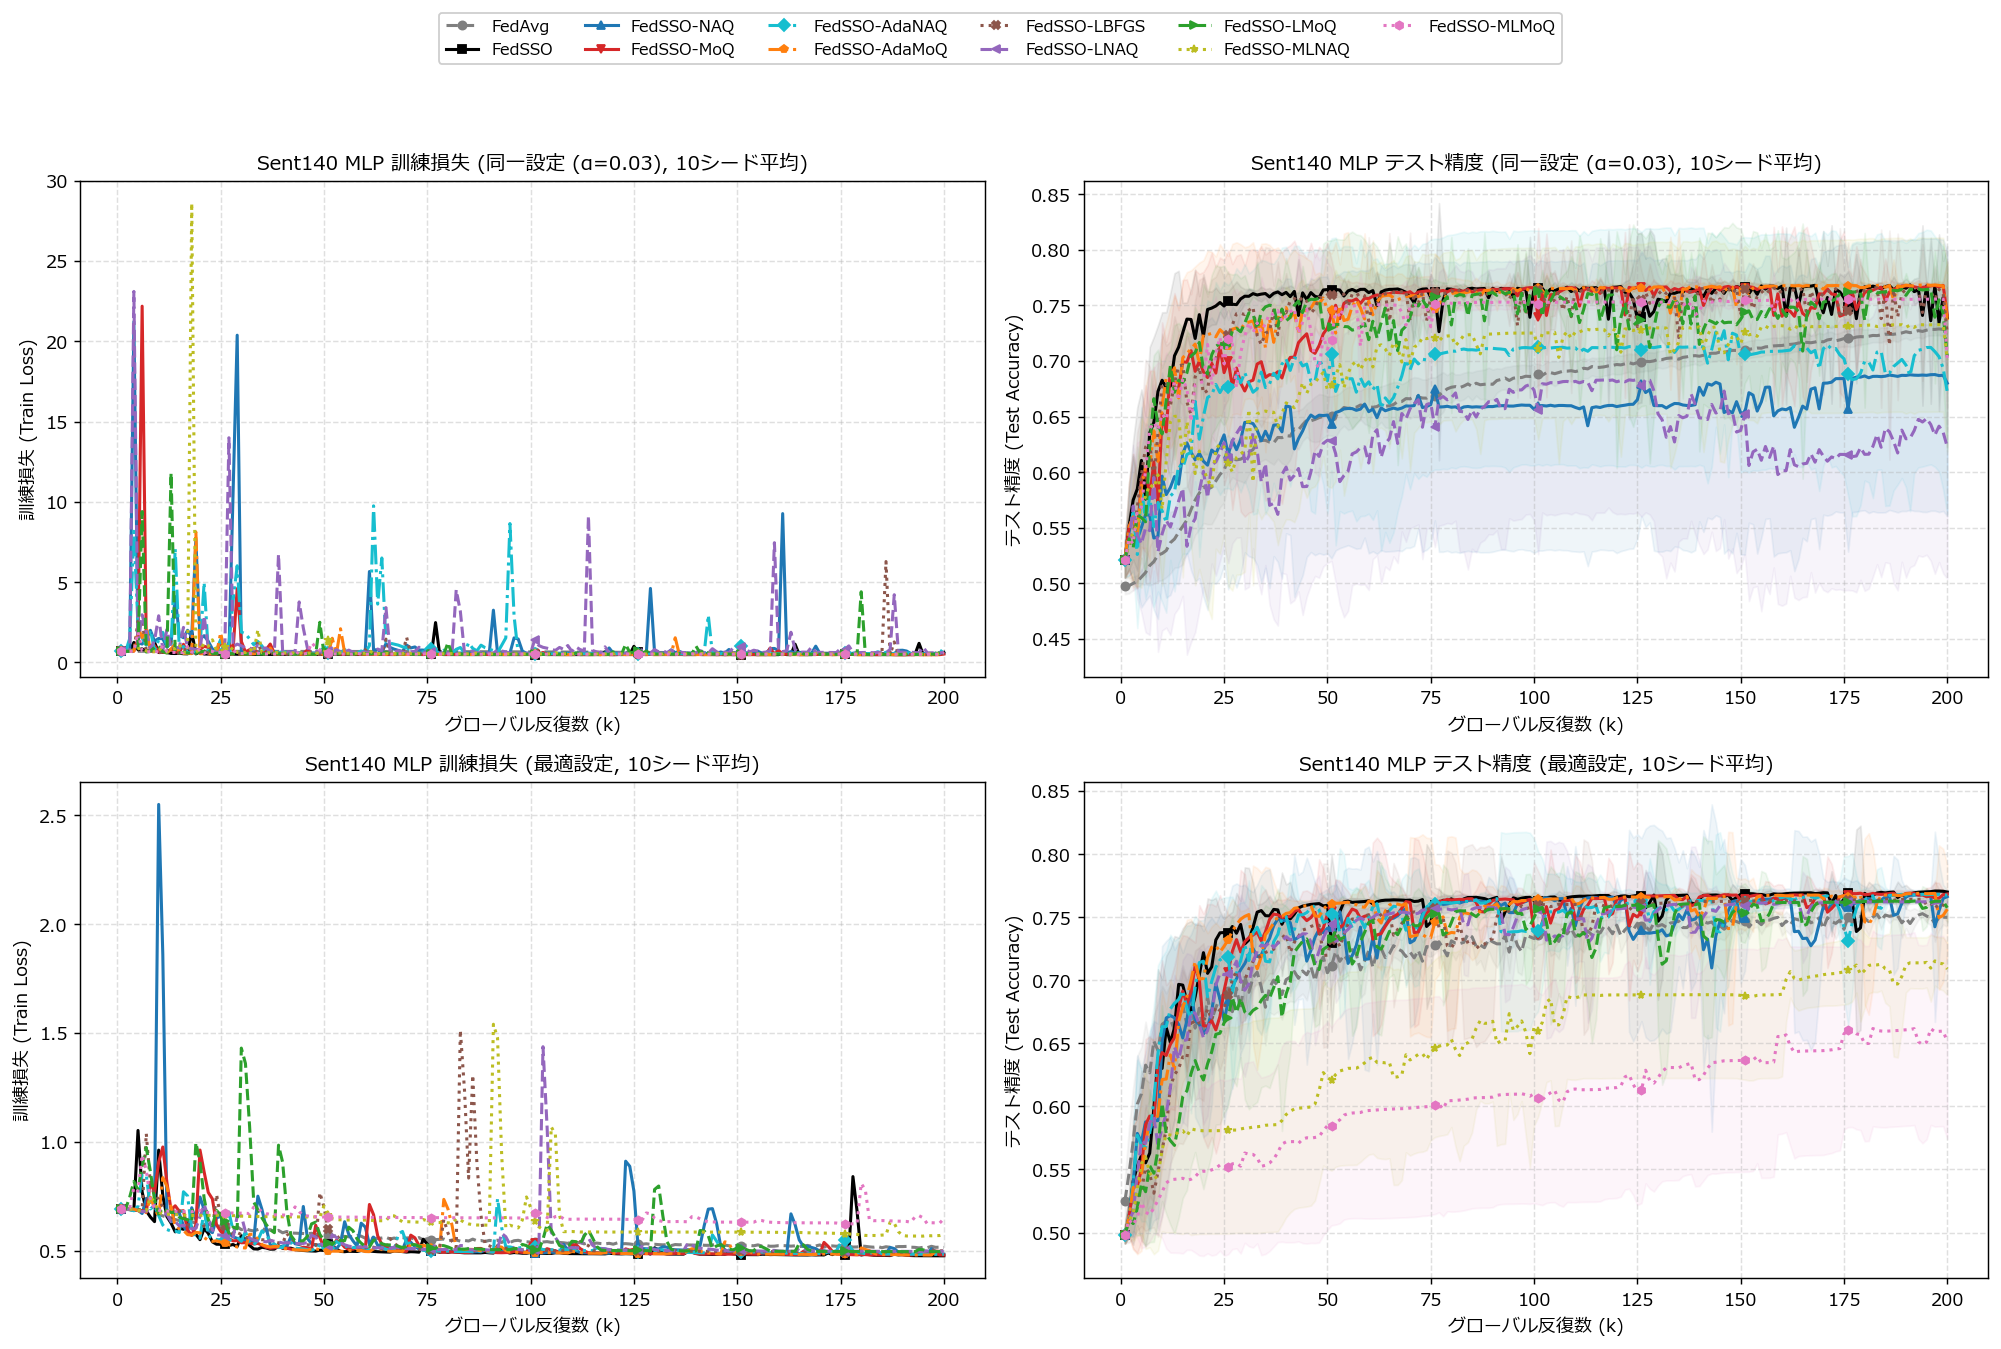

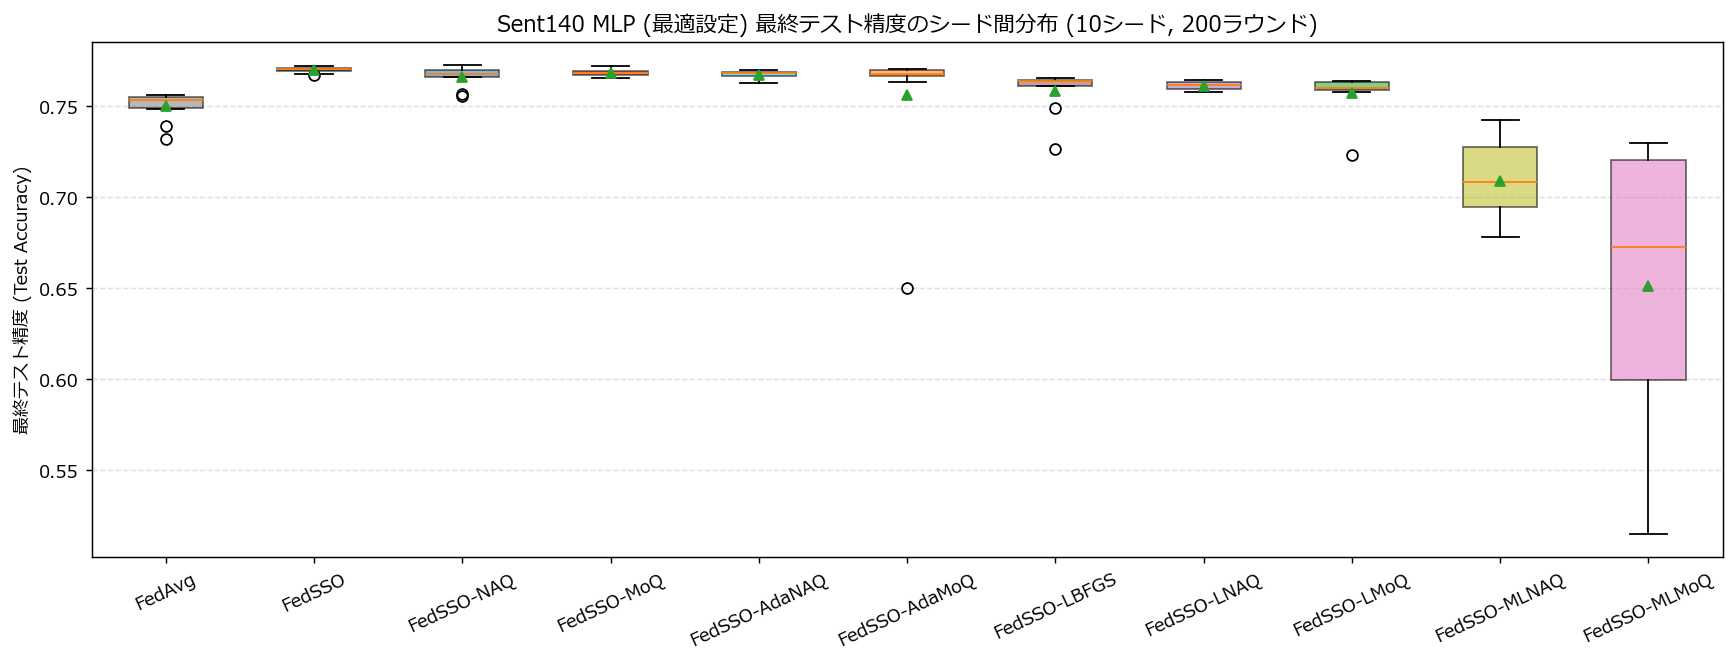

In [4]:
os.makedirs("../report/img", exist_ok=True)
plot_sent140_curves(curves_same, curves_opt, save_path="../report/img/ex010_sent140_mlp_curves.png")
plot_sent140_boxplot(ps_opt, save_path="../report/img/ex010_sent140_mlp_boxplot.png")

## 特定のシード値・アルゴリズムに絞ったグラフ表示

保存済みの全履歴 CSV（`../datasets/ex010_sent140_mlp_opt_history.csv`）から任意のアルゴリズム・シード値だけを指定して再描画できます。 `SELECTED_SEEDS = None` のときは全シード平均のみを自動表示・出力します。

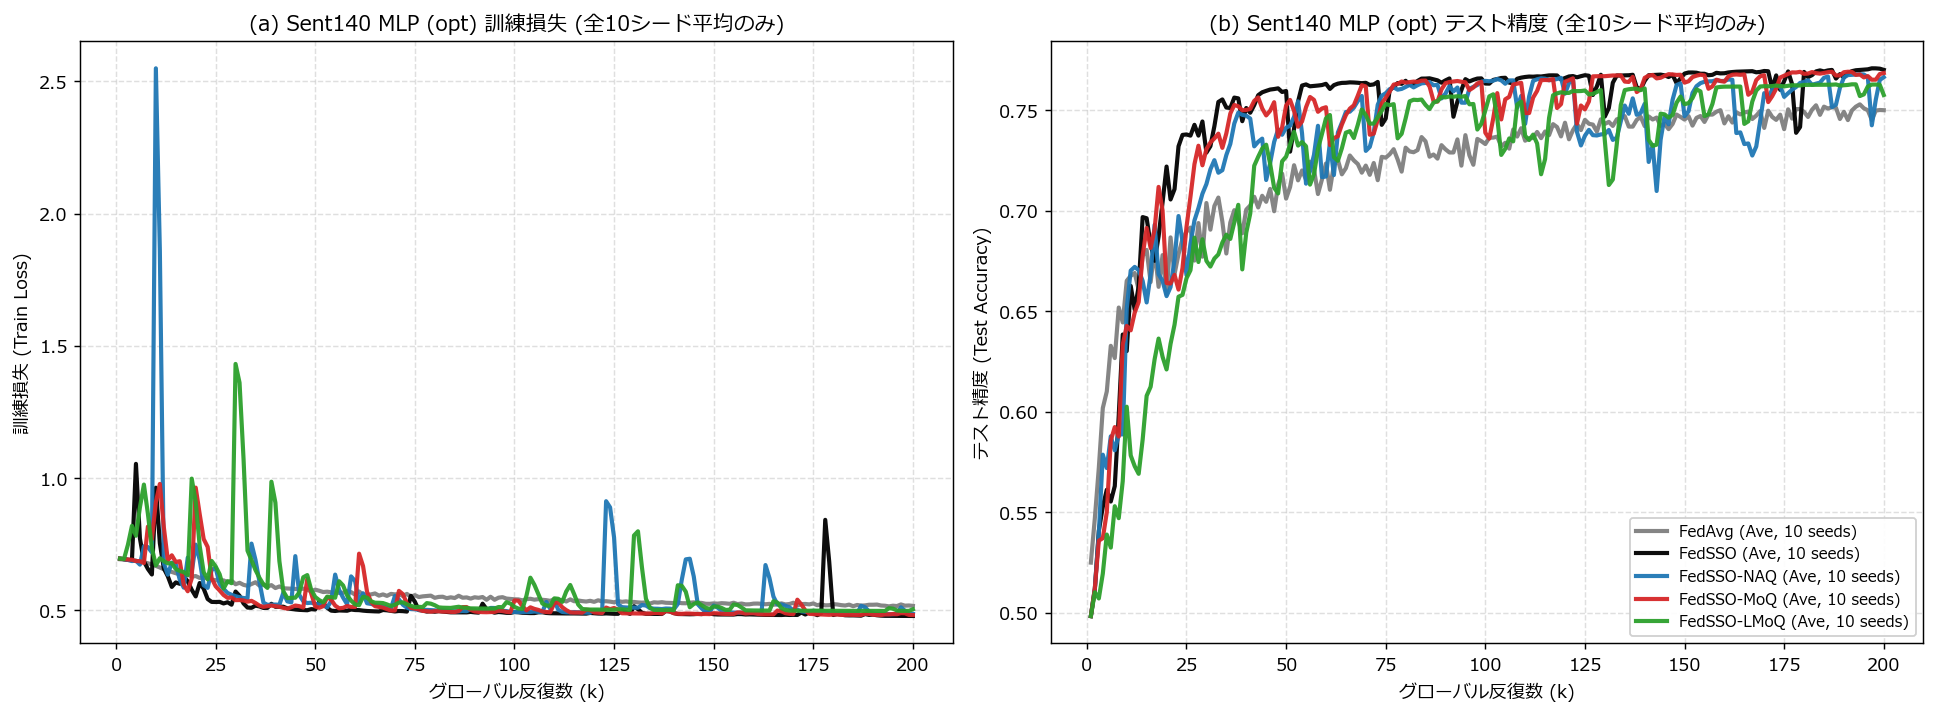

,Algorithm,Seeds,Round,Comm_Round,Train_Loss_Ave,Test_Acc_Ave
0,FedAvg,10,200,200.0,0.515628,0.749916
1,FedSSO,10,200,200.0,0.477486,0.769980
2,FedSSO-NAQ,10,200,399.0,0.485275,0.766336
3,FedSSO-MoQ,10,200,200.0,0.481010,0.768392
4,FedSSO-LMoQ,10,200,200.0,0.502577,0.757484


In [5]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示
# 利用可能なアルゴリズム:
#   ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-AdaMoQ",
#    "FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ", "FedSSO-MLNAQ", "FedSSO-MLMoQ"]
#   None を指定すると全手法が対象になります
# 利用可能なシード値: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] (None で全シード対象)
SELECTED_ALGOS = ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-LMoQ"]
SELECTED_SEEDS = None       # None で全10シード対象（例: [42, 46] で特定シードに絞り込み）
X_AXIS_MODE = "round"       # "round" (反復数) または "comm" (累積通信ラウンド数)
SHOW_MEAN_CURVE = True      # 複数シード指定時に平均太線を重ね描きするか
PLOT_MEAN_ONLY = "auto"     # "auto": SELECTED_SEEDS=None 時に平均線のみ描画 / True: 平均のみ / False: 個別シードも描画
TABLE_MEAN_ONLY = "auto"    # "auto": SELECTED_SEEDS=None 時に平均のみの行を出力 / True: 平均のみ / False: シード別に出力

filtered_df = plot_filtered_results(
    selected_algos=SELECTED_ALGOS,
    selected_seeds=SELECTED_SEEDS,
    setting_tag="opt",
    history_csv_path="../datasets/ex010_sent140_mlp_opt_history.csv",
    log_dir="../datasets/ex010_sent140_mlp_logs",
    x_axis=X_AXIS_MODE,
    show_mean=SHOW_MEAN_CURVE,
    plot_mean_only=PLOT_MEAN_ONLY,
    table_mean_only=TABLE_MEAN_ONLY,
)
filtered_df